# NB2 — Does path structure still matter once variance is fixed?

**Question.** After calibrating the forward scale and checking the backward scale, how much does
the skip weight α change how well a deep residual MLP trains under a fixed budget, and does it act
only through the effective depth L(1−α²)?

**Contents.** 0 Hypotheses · 1 Design · 2 Core code · 3 Control checks · 4 Learning-rate sweep ·
5 Final runs · 6 Results · 7 Mechanism · 8 Effective-depth test · 9 Sensitivity check ·
10 Optional parameter-matched control · 11 Conclusions and scope

In [42]:
QUICK = True  # Submission target: cached runs in under five minutes on the lab kernel.

## Setup

In [31]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

import config as C
from utils import (env_report, get_device, set_seed, make_generator, load_fashion_mnist,
                   iterate_minibatches, evaluate, save_result, result_exists, load_results,
                   summarise, plot_mean_sd, plot_seed_points)

T0 = time.time()
ENV = env_report()
DEVICE = get_device()
DATA = load_fashion_mnist(device=DEVICE, n_val=C.N_VAL, split_seed=C.SPLIT_SEED,
                          n_calib=C.N_CALIB, calib_seed=C.CALIB_SEED)
print({k: tuple(v.shape) for k, v in DATA.items() if torch.is_tensor(v)})

         python: 3.9.6
       platform: macOS-27.2.1-arm64-arm-64bit
          torch: 2.8.0
          numpy: 2.0.2
 cuda_available: False
  mps_available: True
         device: mps
    torchvision: 0.23.0
     matplotlib: 3.9.4
{'x_train': (50000, 784), 'y_train': (50000,), 'x_val': (10000, 784), 'y_val': (10000,), 'x_test': (10000, 784), 'y_test': (10000,), 'x_calib': (512, 784)}


## 0. Hypotheses and pre-registration

- **Protocol commit:** `8381cc9`
- **Date:** 26 November 2026 (UTC)
- **Hypotheses and decision rules:** [hypotheses.md](hypotheses.md)

The protocol uses six epochs for the main experiment, twelve epochs for the
sensitivity check, and a usable-learning-rate threshold of τ = 0.316131.

## 1. Design

**Skip weight and depth.** We vary the skip weight $\alpha$ within each
depth to change the balance between the skip and residual branches at
initialisation. We first characterise how six-epoch training loss changes
with $\alpha$ in the 32-block networks. We repeat the manipulation at
16 blocks to test whether the relationship with effective depth
$L(1-\alpha^2)$ predicts training loss across depths.

**Learning-rate tuning.** The residual-branch weight scale changes with
$\alpha$, so the same learning rate can produce different update sizes
relative to the initial weights. We tune the learning rate separately for
each condition using the same selection rule. We fix SGD momentum at 0.9,
batch size at 128 and the main training budget at six epochs so the
comparisons use a common training protocol. The 12-epoch sensitivity check
examines whether the pattern of training loss across skip weights persists
with a longer budget.

**Conditions and seeds.** The grid includes $\alpha=0$ for a plain network,
$\alpha=1/\sqrt{2}$ for the textbook rescaling condition, and larger values
that give more weight to the skip connection. Four pairs use values of
$\alpha$ chosen to give exactly the same effective depth at 16 and 32
blocks. Each matched condition uses five final seeds to improve the
precision of the paired comparison. The other conditions use three.

In [11]:
print(f"{'depth':>5} {'alpha':>7} {'L(1-a^2)':>9}")
for depth, alphas in C.ALPHAS.items():
    for a in alphas:
        print(f"{depth:>5} {a:>7.4f} {C.effective_depth(depth, a):>9.2f}")
print("matched pairs:", [(p, q, round(C.effective_depth(*p), 2), round(C.effective_depth(*q), 2))
                         for p, q in C.MATCHED_PAIRS])

depth   alpha  L(1-a^2)
   32  0.0000     32.00
   32  0.5000     24.00
   32  0.7071     16.00
   32  0.7906     12.00
   32  0.9000      6.08
   32  0.9700      1.89
   16  0.0000     16.00
   16  0.5000     12.00
   16  0.7071      8.00
   16  0.7874      6.08
   16  0.9000      3.04
   16  0.9390      1.89
   16  0.9700      0.95
matched pairs: [((32, 0.7071067811865476), (16, 0.0), 16.0, 16.0), ((32, 0.7905694150420949), (16, 0.5), 12.0, 12.0), ((32, 0.9), (16, 0.7874007874011811), 6.08, 6.08), ((32, 0.97), (16, 0.9390420650854784), 1.89, 1.89)]


## 2. Core code

Same definitions as NB1 §1, §4 and §5 so that this notebook runs on its own.
**Keep them identical to NB1**: if you change one, change both.

In [32]:
class ResMLP(nn.Module):

    def __init__(self, depth: int, width: int = C.WIDTH, alpha: float = 0.0):
        super().__init__()
        self.alpha = alpha
        self.input_layer = nn.Linear(C.IN_DIM, width, bias=False)
        self.blocks = nn.ModuleList(
            nn.Linear(width, width, bias=False) for _ in range(depth)
        )
        self.output_layer = nn.Linear(width, C.N_CLASSES, bias=False)

    def forward(self, x: torch.Tensor, return_hidden: bool = False):
        x = x.flatten(start_dim=1)
        h = self.input_layer(x)

        if return_hidden:
            hidden = [h]

        for block in self.blocks:
            h = self.alpha * h + block(torch.relu(h))
            if return_hidden:
                hidden.append(h)

        logits = self.output_layer(h)
        if return_hidden:
            return logits, hidden
        return logits

In [33]:
@torch.no_grad()
def init_weights(model: ResMLP, alpha: float, sigma2_block: "float | None" = None) -> None:
    width = model.input_layer.out_features

    if sigma2_block is None:
        sigma2_block = 2 * (1 - alpha ** 2) / width

    model.input_layer.weight.normal_(
        mean=0.0,
        std=model.input_layer.in_features ** -0.5,
    )
    for block in model.blocks:
        block.weight.normal_(mean=0.0, std=sigma2_block ** 0.5)

    model.output_layer.weight.normal_(mean=0.0, std=width ** -0.5)

In [34]:
@torch.no_grad()
def calibrate(model: ResMLP, x_calib: torch.Tensor, alpha: float) -> list[float]:
    h = model.input_layer(x_calib.flatten(start_dim=1))
    scales = []

    for block in model.blocks:
        branch = block(torch.relu(h))
        a = branch.square().mean()
        b = (h * branch).mean()
        c = h.square().mean()

        if a.item() == 0:
            raise ValueError("Cannot calibrate a residual branch with zero output.")

        root = torch.sqrt((alpha * b).square() + (1 - alpha**2) * a * c)
        scale = (root - alpha * b) / a

        block.weight.mul_(scale)
        h = alpha * h + scale * branch
        scales.append(scale.item())

    return scales

In [35]:
def train_one_run(depth: int, alpha: float, lr: float, seed: int, epochs: int = C.EPOCHS,
                  width: int = C.WIDTH, data: dict = None, save: bool = True,
                  with_test: bool = False, n_train: "int | None" = None, tag: str = "") -> dict:
    data = DATA if data is None else data
    set_seed(seed)
    device = data["x_calib"].device
    model = ResMLP(depth=depth, width=width, alpha=alpha).to(device)

    init_weights(model, alpha)
    calibrate(model, data["x_calib"], alpha)

    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=C.MOMENTUM)
    generator = make_generator(seed)
    x_train = data["x_train"]
    y_train = data["y_train"]
    if n_train is not None:
        x_train = x_train[:n_train]
        y_train = y_train[:n_train]
        save = False 

    train_loss, val_loss = [], []
    train_acc, val_acc = [], []
    diverged = False
    start_time = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        for xb, yb in iterate_minibatches(
            x_train, y_train, C.BATCH_SIZE, generator=generator
        ):
            optimizer.zero_grad()
            logits = model(xb)
            loss = nn.functional.cross_entropy(logits, yb)

            if not torch.isfinite(loss).item():
                diverged = True
                break

            loss.backward()
            optimizer.step()

        if diverged:
            break

        train_metrics = evaluate(model, x_train, y_train)
        val_metrics = evaluate(model, data["x_val"], data["y_val"])

        if not (np.isfinite(train_metrics["loss"]) and np.isfinite(val_metrics["loss"])):
            diverged = True
            break

        train_loss.append(train_metrics["loss"])
        train_acc.append(train_metrics["acc"])
        val_loss.append(val_metrics["loss"])
        val_acc.append(val_metrics["acc"])
        
    record = {
        "depth": depth,
        "width": width,
        "alpha": alpha,
        "lr": lr,
        "seed": seed,
        "epochs": epochs,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc,
        "final_train_loss": None if diverged else train_loss[-1],
        "diverged": diverged,
        "seconds": time.perf_counter() - start_time,
    }

    if with_test:
        record["test_loss"] = None
        record["test_acc"] = None
        if not diverged:
            test_metrics = evaluate(model, data["x_test"], data["y_test"])
            record["test_loss"] = test_metrics["loss"]
            record["test_acc"] = test_metrics["acc"]

    if save:
        save_result(record, tag=tag)

    return record

In [36]:
trial = train_one_run(
    depth=2,
    alpha=C.ALPHA_BASELINE,
    lr=0.001,
    seed=0,
    epochs=1,
    n_train=256,
    save=False,
)

print(trial["diverged"], len(trial["train_loss"]), trial["final_train_loss"])

False 1 2.491852283477783


## 3. Control check: forward and backward second moments at initialisation

Measurements:

In [37]:
@torch.no_grad()
def forward_second_moment_ratios(model, x):
    _, hidden = model(x, return_hidden=True)
    moments = np.array([h.square().mean().item() for h in hidden])
    return moments / moments[0]


x_check = DATA["x_val"][:512]
y_check = DATA["y_val"][:512]
control_seeds = (100, 101, 102)

print("Depth   Alpha   Max calib deviation   Held-out hL/h0   Backward/block   Last-layer grad M2")

for depth, alphas in C.ALPHAS.items():
    for alpha in alphas:
        measurements = []
        for seed in control_seeds:
            set_seed(seed)
            model = ResMLP(depth=depth, width=C.WIDTH, alpha=alpha).to(DEVICE)
            init_weights(model, alpha)
            calibrate(model, DATA["x_calib"], alpha)
            model.eval()

            calib_ratios = forward_second_moment_ratios(model, DATA["x_calib"])
            held_out_ratios = forward_second_moment_ratios(model, x_check)

            logits, hidden = model(x_check, return_hidden=True)
            loss = nn.functional.cross_entropy(logits, y_check)
            grads = torch.autograd.grad(loss, hidden)
            grad_moments = [g.square().mean().item() for g in grads]
            backward_factor = (grad_moments[0] / grad_moments[-1]) ** (1 / depth)

            measurements.append((
                np.max(np.abs(calib_ratios - 1.0)),
                held_out_ratios[-1],
                backward_factor,
                grad_moments[-1],
            ))

        measurements = np.asarray(measurements)
        max_deviation = measurements[:, 0].max()
        held_out, backward, grad_level = measurements[:, 1:].mean(axis=0)
        print(f"{depth:>5}   {alpha:>5.4f}   {max_deviation:>19.2e}"
              f"   {held_out:>14.4f}   {backward:>14.4f}   {grad_level:>18.2e}")

Depth   Alpha   Max calib deviation   Held-out hL/h0   Backward/block   Last-layer grad M2
   32   0.0000              1.05e-06           1.0055           1.0041             1.50e-08
   32   0.5000              5.85e-07           0.9776           1.0122             1.41e-08
   32   0.7071              1.05e-06           0.9864           1.0016             1.42e-08
   32   0.7906              6.62e-07           0.9850           1.0047             1.45e-08
   32   0.9000              1.57e-06           0.9969           1.0029             1.44e-08
   32   0.9700              1.87e-06           1.0018           1.0018             1.43e-08
   16   0.0000              8.65e-07           1.0019           0.9910             1.57e-08
   16   0.5000              3.61e-07           0.9687           1.0070             1.52e-08
   16   0.7071              5.85e-07           0.9777           0.9987             1.43e-08
   16   0.7874              1.85e-07           0.9896           1.0006           

Across the 13 conditions, the largest deviation from the input-layer
activation second moment on the calibration batch was 1.87e-6.
On a held-out validation batch, the final-to-input activation second-moment
ratio ranged from 0.9687 to 1.0055 across the condition means. The largest
deviation occurred at 16 blocks and α = 0.5.

The mean per-block geometric factor for backward gradient second moments
ranged from 0.9910 to 1.0122. These measurements support comparing the
conditions under similar signal scales at initialisation.

## 4. Learning-rate sweep (seed 0)

Each condition is swept over `C.LR_GRID`; the grid is extended where the best value or an edge
of the usable range sits on the grid edge. Runs already in `results/` are skipped, so the sweep
can be resumed.

In [18]:
def sweep(depth: int, alpha: float, lr_grid=C.LR_GRID) -> list[dict]:
    """Run the seed-0 learning-rate sweep for one condition."""

    records = []
    # Remove duplicates and sort learning rates.
    lr_grid = sorted({_lr_key(lr) for lr in lr_grid})

    for lr in lr_grid:
        if lr <= 0 or not np.isfinite(lr):
            raise ValueError(f"Invalid learning rate: {lr}")

        if result_exists(
            depth=depth,
            alpha=alpha,
            lr=lr,
            seed=C.TUNE_SEED,
            epochs=C.EPOCHS,
            tag="",
            width=C.WIDTH,
        ):
            print(f"Skip existing run: lr={lr:g}", flush=True)

            record = _load_one(
                depth, alpha, lr, C.TUNE_SEED, C.WIDTH, ""
            )
        else:
            if QUICK:
                raise RuntimeError(
                    f"QUICK mode: missing sweep result for "
                    f"depth={depth}, alpha={alpha}, lr={lr:g}"
                )

            print(f"Training: lr={lr:g}", flush=True)

            record = train_one_run(
                depth=depth,
                alpha=alpha,
                lr=lr,
                seed=C.TUNE_SEED,
                epochs=C.EPOCHS,
                width=C.WIDTH,
                save=True,
                tag="",
            )

        records.append(record)

    return records



# τ = 1.25 × L_base, fixed from the seed-0 baseline at the learning rate the selection rule
# picks for it (32 blocks, α = 1/√2). The baseline was tuned before the main sweep existed, so its
# runs carry BASELINE_TAG; switch it to "" once the baseline is re-run with the main conditions.
BASELINE_TAG = "baseline_tune_v2"

# A learning rate is usable when the seed-0 run does
# not diverge and its final training loss is at most τ. hypotheses.md § "Usable
# learning-rate threshold" and § "Learning-rate grid, extension and tie-break".
TIEBREAK_SEED = 6          # outside the final seeds 1–5; same extra seed as the baseline
TIEBREAK_TAG = "tiebreak"
TIE_REL = 0.05
LR_EXTEND = 3.0
MAX_LR_EXTENSIONS = 8


def _lr_key(lr: float) -> float:
    return float(f"{float(lr):.8g}")


def _final_loss(record: dict):
    if record.get("diverged") or record.get("final_train_loss") is None:
        return None
    loss = float(record["final_train_loss"])
    if not np.isfinite(loss):
        return None
    return loss


def _within_rel(a: float, b: float, rel: float = TIE_REL) -> bool:
    """True when the two losses differ by strictly less than `rel` of the lower one."""
    lo = min(a, b)
    if lo <= 0:
        return a == b
    return (max(a, b) - lo) / lo < rel


def usable_tau() -> float:
    """tau = 1.25 x the seed-0 baseline loss at the learning rate the selection rule picks.

    Reads the seed-0 sweep of the baseline condition at the main epoch budget and takes the
    lowest final loss, which is the same rule select_lr() applies. Deriving tau here rather than
    hard-coding a learning rate keeps it correct when the budget changes.
    """
    runs = load_results(
        tag=BASELINE_TAG,
        depth=C.DEPTH_MAIN,
        width=C.WIDTH,
        alpha=C.ALPHA_BASELINE,
        seed=C.TUNE_SEED,
        epochs=C.EPOCHS,
    )
    finished = [record for record in runs if _final_loss(record) is not None]
    if not finished:
        raise RuntimeError(
            f"no finished baseline sweep tagged {BASELINE_TAG!r} at {C.EPOCHS} epochs"
        )
    best = min(finished, key=_final_loss)
    return 1.25 * _final_loss(best)


def _is_usable(record: dict, tau: float) -> bool:
    loss = _final_loss(record)
    return loss is not None and loss <= tau


def _load_one(depth, alpha, lr, seed, width, tag):
    found = load_results(
        depth=depth, alpha=alpha, lr=_lr_key(lr), seed=seed,
        epochs=C.EPOCHS, width=width, tag=tag,
    )
    if len(found) != 1:
        raise RuntimeError(
            f"expected one saved run depth={depth} alpha={alpha} lr={_lr_key(lr):g} "
            f"seed={seed} tag={tag!r}; found {len(found)}"
        )
    return found[0]


def _ensure_run(depth, alpha, lr, seed, width, tag):
    """Return the saved run, training it only when this is not a QUICK session."""
    lr = _lr_key(lr)
    if result_exists(depth, alpha, lr, seed, C.EPOCHS, tag=tag, width=width):
        return _load_one(depth, alpha, lr, seed, width, tag)
    if QUICK:
        raise RuntimeError(
            "QUICK mode will not train a missing run: "
            f"depth={depth} alpha={alpha} lr={lr:g} seed={seed} tag={tag!r}"
        )
    print(f"depth={depth} alpha={alpha:.4f} lr={lr:g} seed={seed}: training", flush=True)
    return train_one_run(
        depth=depth, alpha=alpha, lr=lr, seed=seed, epochs=C.EPOCHS,
        width=width, save=True, tag=tag,
    )


def _seed0_by_lr(depth, alpha, width):
    found = load_results(
        depth=depth, alpha=alpha, width=width, seed=C.TUNE_SEED,
        epochs=C.EPOCHS, tag="",
    )
    by_lr = {}
    for record in found:
        key = _lr_key(record["lr"])
        if key in by_lr:
            raise RuntimeError(
                f"duplicate seed-0 run at depth={depth} alpha={alpha} lr={key:g}"
            )
        by_lr[key] = record
    return by_lr


def _extend_grid(by_lr, depth, alpha, width, tau):
    """Train ×3 / ÷3 points until both ends fail and the best seed-0 loss is interior.

    An end fails when that run diverges or its final loss is above τ. A side is still
    open when its endpoint is usable, or when the best loss sits on that endpoint.
    """
    steps = 0
    while True:
        grid = sorted(by_lr)
        finite = [lr for lr in grid if _final_loss(by_lr[lr]) is not None]
        if not finite:
            raise RuntimeError(
                f"depth={depth} alpha={alpha}: every seed-0 learning rate diverged"
            )
        best = min(finite, key=lambda lr: _final_loss(by_lr[lr]))
        lo, hi = grid[0], grid[-1]
        extend_lo = best == lo or _is_usable(by_lr[lo], tau)
        extend_hi = best == hi or _is_usable(by_lr[hi], tau)
        if not extend_lo and not extend_hi:
            return by_lr
        if steps >= MAX_LR_EXTENSIONS:
            raise RuntimeError(
                f"depth={depth} alpha={alpha:.4f}: learning-rate grid still open after "
                f"{MAX_LR_EXTENSIONS} extensions (ends {lo:g} and {hi:g}, best={best:g})"
            )
        steps += 1
        if extend_lo:
            new_lr = _lr_key(lo / LR_EXTEND)
            if new_lr >= lo:
                raise RuntimeError(f"refusing to extend the low end from {lo:g} to {new_lr:g}")
            print(f"depth={depth} alpha={alpha:.4f}: extend low end to lr={new_lr:g}", flush=True)
            by_lr[new_lr] = _ensure_run(depth, alpha, new_lr, C.TUNE_SEED, width, "")
        if extend_hi:
            new_lr = _lr_key(hi * LR_EXTEND)
            if new_lr <= hi:
                raise RuntimeError(f"refusing to extend the high end from {hi:g} to {new_lr:g}")
            print(f"depth={depth} alpha={alpha:.4f}: extend high end to lr={new_lr:g}", flush=True)
            by_lr[new_lr] = _ensure_run(depth, alpha, new_lr, C.TUNE_SEED, width, "")


def select_lr(depth: int, alpha: float, width: int = C.WIDTH) -> float:
    """Learning rate for one condition, from the seed-0 sweep.

    The seed-0 run with the lowest final training loss wins. If that learning rate,
    or either end of the usable range, sits on the edge of the grid, train outward
    by ×3 and ÷3 until both ends fail. If the winner and a neighbouring learning rate
    differ by less than 5%, train one extra seed and compare the means; if those
    means are still within 5%, take the smaller learning rate.
    """
    tau = usable_tau()
    by_lr = _seed0_by_lr(depth, alpha, width)
    missing = [lr for lr in C.LR_GRID if _lr_key(lr) not in by_lr]
    if missing:
        raise RuntimeError(
            f"depth={depth} alpha={alpha:.4f}: seed-0 sweep is missing "
            f"{[_lr_key(lr) for lr in missing]}. Run sweep() first."
        )
    _extend_grid(by_lr, depth, alpha, width, tau)

    grid = sorted(by_lr)
    finite = [lr for lr in grid if _final_loss(by_lr[lr]) is not None]
    if not finite:
        raise RuntimeError(
            f"depth={depth} alpha={alpha}: every seed-0 learning rate diverged"
        )
    best = min(finite, key=lambda lr: (_final_loss(by_lr[lr]), lr))
    best_loss = _final_loss(by_lr[best])
    i = grid.index(best)
    tied = [best]
    for j in (i - 1, i + 1):
        if not 0 <= j < len(grid):
            continue
        neighbour = _final_loss(by_lr[grid[j]])
        if neighbour is not None and _within_rel(neighbour, best_loss):
            tied.append(grid[j])

    if len(tied) == 1:
        chosen = best
        note = ""
    else:
        means = {}
        for lr in tied:
            extra = _ensure_run(depth, alpha, lr, TIEBREAK_SEED, width, TIEBREAK_TAG)
            extra_loss = _final_loss(extra)
            means[lr] = (
                float("inf") if extra_loss is None else (best_loss if lr == best else _final_loss(by_lr[lr]) + extra_loss) / 2
                if extra_loss is not None else float("inf")
            )
            if extra_loss is None:
                means[lr] = float("inf")
            else:
                means[lr] = (_final_loss(by_lr[lr]) + extra_loss) / 2.0
        finite_means = {lr: m for lr, m in means.items() if np.isfinite(m)}
        if not finite_means:
            raise RuntimeError(
                f"depth={depth} alpha={alpha}: tie-break seed {TIEBREAK_SEED} "
                "diverged for every close learning rate"
            )
        best_mean = min(finite_means.values())
        close = [lr for lr, m in finite_means.items() if _within_rel(m, best_mean)]
        chosen = min(close)
        if len(close) > 1:
            note = (
                f"; tie-break seed {TIEBREAK_SEED}, means still within 5%, "
                "took the smaller lr"
            )
        else:
            note = f"; tie-break seed {TIEBREAK_SEED}, took the lower mean"

    print(
        f"depth={depth} alpha={alpha:.4f}: selected lr={chosen:g} (τ={tau:.4f}{note})",
        flush=True,
    )
    return chosen


if not QUICK:
    for depth, alphas in C.ALPHAS.items():
        for alpha in alphas:
            sweep(depth, alpha)

## 5. Final runs (seeds 1–3; 1–5 for the matched-pair conditions)

In [19]:
# §5, step 1: the learning rate of every condition, by the rule in hypotheses.md § "Learning-rate
# grid, extension and tie-break". select_lr() trains outward when the best rate or an end of the
# usable range sits on the grid edge, and adds one seed when two neighbouring rates are within 5%,
# so this step can produce runs of its own. Everything it trains is saved, so a failure below can
# be resumed.
#
# The choice is written next to the notebooks and not into results/: load_results() globs
# results/*.json and would read a config file as if it were a training run.

import json
from pathlib import Path

from utils import git_commit, ROOT as REPO_ROOT

# Anchored to the repository so it lands next to the notebooks whatever the working
# directory of the kernel is.
SELECTED_LR_PATH = Path(REPO_ROOT) / "selected_lr.json"


def save_selected_lr(chosen: dict, path=SELECTED_LR_PATH) -> Path:
    payload = {
        "_meta": {"saved_at": time.strftime("%Y-%m-%d %H:%M:%S"), "epochs": C.EPOCHS,
                  "tune_seed": C.TUNE_SEED, "git_commit": git_commit()},
        "selected_lr": [{"depth": d, "alpha": a, "lr": lr}
                        for (d, a), lr in sorted(chosen.items())],
    }
    Path(path).write_text(json.dumps(payload, indent=1))
    return Path(path)


def load_selected_lr(path=SELECTED_LR_PATH) -> dict:
    payload = json.loads(Path(path).read_text())
    return {(row["depth"], row["alpha"]): row["lr"] for row in payload["selected_lr"]}


if not QUICK:
    chosen, failed = {}, {}
    for depth, alphas in C.ALPHAS.items():
        for alpha in alphas:
            try:
                chosen[(depth, alpha)] = select_lr(depth, alpha, C.WIDTH)
            except Exception as error:      # keep going: the other conditions are still worth doing
                failed[(depth, alpha)] = f"{type(error).__name__}: {error}"
                print(f"FAILED depth={depth} alpha={alpha:.4f}: {failed[(depth, alpha)]}",
                      flush=True)
    if chosen:
        saved = save_selected_lr(chosen)
        print(f"\n{len(chosen)} of {len(chosen) + len(failed)} learning rates written to {saved}")
        for (depth, alpha), lr in sorted(chosen.items()):
            print(f"  depth={depth:>2}  alpha={alpha:.4f}  lr={lr:g}")
    if failed:
        print(f"\n{len(failed)} condition(s) did not resolve: {sorted(failed)}")

In [20]:
# §5, step 2: the final runs at the chosen learning rate - seeds 1-3, and 1-5 for the eight
# matched-pair conditions (config.final_seeds). Resumable: runs already on disk are skipped, so an
# interrupted batch can simply be started again.
FINAL_TAG = "final"

if not QUICK:
    chosen = load_selected_lr()
    planned = [(depth, alpha, seed) for depth, alphas in C.ALPHAS.items() for alpha in alphas
               for seed in C.final_seeds(depth, alpha)]
    print(f"{len(planned)} final runs planned at {C.EPOCHS} epochs", flush=True)
    done = 0
    for index, (depth, alpha, seed) in enumerate(planned, 1):
        run = dict(depth=depth, alpha=alpha, lr=chosen[(depth, alpha)], seed=seed,
                   epochs=C.EPOCHS, width=C.WIDTH)
        if result_exists(**run, tag=FINAL_TAG):
            continue
        record = train_one_run(**run, with_test=True, save=True, tag=FINAL_TAG)
        done += 1
        if record["diverged"]:
            state = "diverged"
        else:
            state = (f"loss={record['final_train_loss']:.4f} "
                     f"test_acc={record['test_acc']:.2%}")
        print(f"[{index}/{len(planned)}] depth={depth} alpha={alpha:.4f} seed={seed} "
              f"lr={run['lr']:g}: {state} ({record['seconds']:.0f} s)", flush=True)
    print(f"\ntrained {done} of {len(planned)} final runs")

## 6. Results

- 6a. Training-loss curves per α (32 blocks), mean ± sd over seeds.
- 6b. Final training loss against α (32 blocks), one point per seed.
- 6c. Final training loss against learning rate for every condition: shows tuning is fair and gives
  the usable range.
- 6d. Training loss after epoch `C.EARLY_EPOCH` against α: training speed, useful if the final
  losses are close.

_TODO: apply the decision rules from §0 and say what each figure shows. Diverged runs are listed,
not dropped._

In [21]:
# Figures 6a-6d and the table the decision rules in §0 are applied to. Everything is read from
# results/: nothing here trains.

def final_runs(depth, alpha, tag=FINAL_TAG):
    """Every saved final run of one condition, sorted by seed, with completeness checked."""
    runs = load_results(tag=tag, depth=depth, width=C.WIDTH, alpha=alpha,
                        epochs=C.EPOCHS)
    runs.sort(key=lambda r: r["seed"])
    expected = list(C.final_seeds(depth, alpha))
    got = [r["seed"] for r in runs]
    if got != expected:
        raise RuntimeError(f"depth={depth} alpha={alpha}: final seeds {got}, expected {expected}")
    return runs


def condition_table(depth):
    """One row per condition: the learning rate used, the finished seeds, mean and sd."""
    rows = []
    for alpha in C.ALPHAS[depth]:
        runs = final_runs(depth, alpha)
        finished = [r for r in runs if not r["diverged"] and r["final_train_loss"] is not None]
        losses = [r["final_train_loss"] for r in finished]
        rows.append(dict(
            depth=depth, alpha=alpha, lr=chosen[(depth, alpha)],
            n=len(finished), n_diverged=len(runs) - len(finished),
            mean=float(np.mean(losses)) if losses else float("nan"),
            sd=float(np.std(losses, ddof=1)) if len(losses) > 1 else float("nan"),
            early=float(np.mean([r["train_loss"][C.EARLY_EPOCH - 1] for r in finished]))
            if finished else float("nan"),
            acc=float(np.mean([r["test_acc"] for r in finished if r.get("test_acc") is not None]))
            if finished else float("nan"),
        ))
    return rows


chosen = load_selected_lr()
table = {depth: condition_table(depth) for depth in C.ALPHAS}

print(f"{'depth':>5} {'alpha':>7} {'lr':>8} {'seeds':>5} {'div':>4} "
      f"{'final train loss':>18} {'epoch-1 loss':>13} {'test acc':>9}")
for depth in sorted(table):
    for row in table[depth]:
        print(f"{row['depth']:>5} {row['alpha']:>7.4f} {row['lr']:>8g} {row['n']:>5} "
              f"{row['n_diverged']:>4} {row['mean']:>11.4f} ± {row['sd']:.4f} "
              f"{row['early']:>13.4f} {row['acc']:>9.2%}")

depth   alpha       lr seeds  div   final train loss  epoch-1 loss  test acc
   16  0.0000    0.002     5    0      0.2523 ± 0.0131        0.4139    86.66%
   16  0.5000    0.003     5    0      0.2383 ± 0.0063        0.3989    87.24%
   16  0.7071    0.003     3    0      0.2258 ± 0.0110        0.3751    87.42%
   16  0.7874    0.003     5    0      0.2177 ± 0.0098        0.3676    87.52%
   16  0.9000    0.003     3    0      0.2085 ± 0.0077        0.3578    87.98%
   16  0.9390    0.005     5    0      0.2013 ± 0.0075        0.3504    88.05%
   16  0.9700    0.003     3    0      0.2128 ± 0.0059        0.3630    87.84%
   32  0.0000    0.003     3    0      0.2875 ± 0.0169        0.5420    86.59%
   32  0.5000    0.001     3    0      0.2713 ± 0.0118        0.4631    86.35%
   32  0.7071    0.002     5    0      0.2453 ± 0.0110        0.4161    86.98%
   32  0.7906    0.001     5    0      0.2507 ± 0.0025        0.4337    86.64%
   32  0.9000    0.005     5    0      0.2119 ± 0.0085

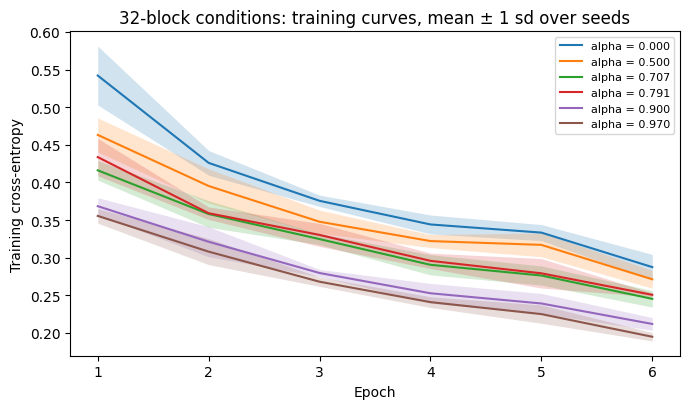

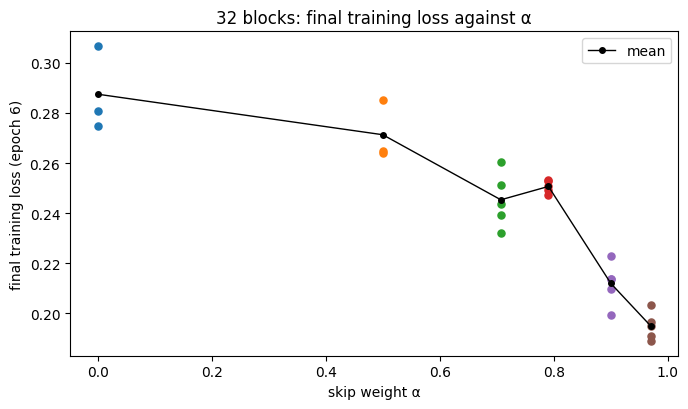

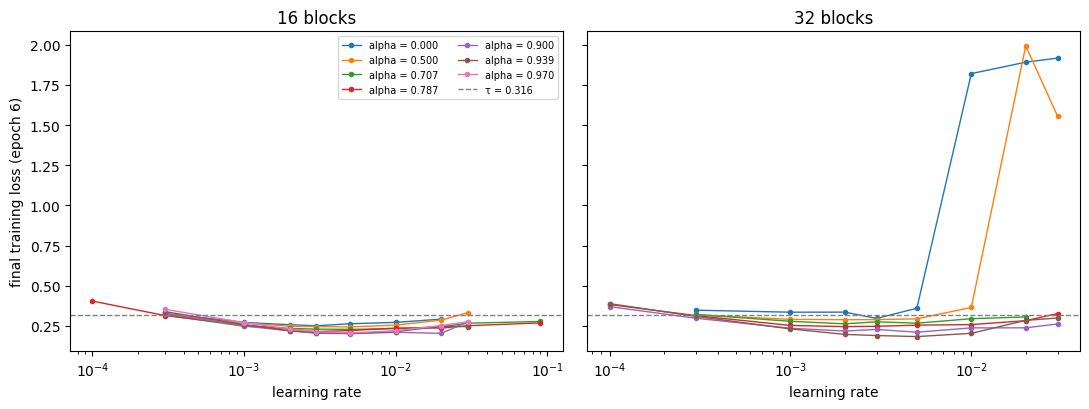

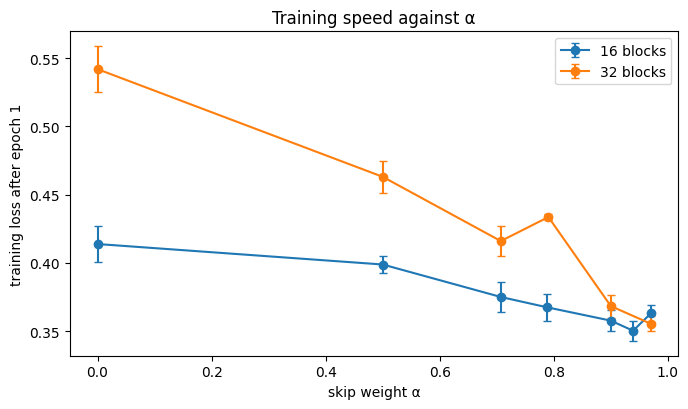

In [22]:
main = C.DEPTH_MAIN
epochs = np.arange(1, C.EPOCHS + 1)
alphas_main = list(C.ALPHAS[main])

# 6a. Training-loss curves per alpha at 32 blocks, mean +- 1 sd over the final seeds.
fig, ax = plt.subplots(figsize=(7, 4.2))
for alpha in alphas_main:
    curves = [r["train_loss"] for r in final_runs(main, alpha)]
    plot_mean_sd(ax, epochs, curves, label=f"alpha = {alpha:.3f}", marker="")
ax.set(xlabel="Epoch", ylabel="Training cross-entropy",
       title=f"{main}-block conditions: training curves, mean ± 1 sd over seeds")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# 6b. Final training loss against alpha at 32 blocks, one point per seed.
fig, ax = plt.subplots(figsize=(7, 4.2))
for alpha in alphas_main:
    ax.scatter([alpha] * len(final_runs(main, alpha)),
               [r["final_train_loss"] for r in final_runs(main, alpha)],
               s=26, label=None)
ax.plot([r["alpha"] for r in table[main]], [r["mean"] for r in table[main]],
        color="black", lw=1, marker="o", ms=4, label="mean")
ax.set(xlabel="skip weight α", ylabel=f"final training loss (epoch {C.EPOCHS})",
       title=f"{main} blocks: final training loss against α")
ax.legend()
fig.tight_layout()
plt.show()

# 6c. Every condition's seed-0 sweep against its learning rate, with tau.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
tau = usable_tau()
for ax, depth in zip(axes, sorted(C.ALPHAS)):
    for alpha in C.ALPHAS[depth]:
        grid = sorted((r for r in load_results(tag="", depth=depth, width=C.WIDTH, alpha=alpha,
                                               seed=C.TUNE_SEED, epochs=C.EPOCHS)
                       if not r["diverged"]), key=lambda r: r["lr"])
        ax.plot([r["lr"] for r in grid], [r["final_train_loss"] for r in grid],
                marker="o", ms=3, lw=1, label=f"alpha = {alpha:.3f}")
    ax.axhline(tau, color="grey", ls="--", lw=1, label=f"τ = {tau:.3f}")
    ax.set(xscale="log", xlabel="learning rate", title=f"{depth} blocks")
axes[0].set_ylabel(f"final training loss (epoch {C.EPOCHS})")
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

# 6d. Training loss after the early epoch against alpha: training speed.
fig, ax = plt.subplots(figsize=(7, 4.2))
for depth in sorted(C.ALPHAS):
    ax.errorbar([r["alpha"] for r in table[depth]], [r["early"] for r in table[depth]],
                yerr=[r["sd"] for r in table[depth]], marker="o", capsize=3,
                label=f"{depth} blocks")
ax.set(xlabel="skip weight α", ylabel=f"training loss after epoch {C.EARLY_EPOCH}",
       title="Training speed against α")
ax.legend()
fig.tight_layout()
plt.show()

## 7. Mechanism: the input–output Jacobian at initialisation

For each condition, J = ∂h_L/∂h_0 at 32 inputs: similarity of J at nearby inputs (gradient
shattering, UDL §11.1), stable rank ‖J‖_F² / ‖J‖₂², and the spectrum of squared singular values
(dynamical isometry, Pennington et al. 2017).

In [45]:
@torch.no_grad()
def block_stack_jacobian(model, h):
    """Return d h_L / d h_0 for one hidden-space input."""
    identity = torch.eye(h.numel(), device=h.device, dtype=h.dtype)
    jacobian = identity

    for block in model.blocks:
        active = (h > 0).to(h.dtype)
        local_jacobian = model.alpha * identity + block.weight * active[None, :]
        jacobian = local_jacobian @ jacobian
        h = model.alpha * h + block(torch.relu(h))

    return jacobian


@torch.no_grad()
def jacobian_metrics(model, h0, eps_scale=0.1, generator=None):
    """Measure nearby-input similarity, stable rank and squared spectra."""
    noise = torch.randn(h0.shape, dtype=h0.dtype, generator=generator)
    nearby = h0 + eps_scale * h0.std() * noise.to(h0.device)

    similarities = []
    stable_ranks = []
    spectra = []

    for h, h_nearby in zip(h0, nearby):
        jacobian = block_stack_jacobian(model, h)
        jacobian_nearby = block_stack_jacobian(model, h_nearby)

        similarity = nn.functional.cosine_similarity(
            jacobian.flatten(), jacobian_nearby.flatten(), dim=0
        )
        similarities.append(similarity.item())

        squared_singular_values = torch.linalg.svdvals(jacobian.cpu()).square()
        stable_ranks.append(
            (squared_singular_values.sum() / squared_singular_values.max()).item()
        )
        spectra.append(squared_singular_values.numpy())

    return {
        "cosine_similarity": float(np.mean(similarities)),
        "stable_rank": float(np.mean(stable_ranks)),
        "squared_singular_values": np.stack(spectra),
    }

In [46]:
torch.manual_seed(0)
small_model = ResMLP(depth=2, width=8, alpha=0.5)
h = torch.randn(8)

def small_block_stack(h):
    for block in small_model.blocks:
        h = small_model.alpha * h + block(torch.relu(h))
    return h

expected = torch.autograd.functional.jacobian(small_block_stack, h)
actual = block_stack_jacobian(small_model, h)
torch.testing.assert_close(actual, expected)

metrics = jacobian_metrics(
    small_model, torch.randn(4, 8), generator=make_generator(0)
)
print("Jacobian check passed")
print("Spectrum shape:", metrics["squared_singular_values"].shape)

Jacobian check passed
Spectrum shape: (4, 8)


## 8. Effective-depth prediction

Use the cached 6-epoch finals at each condition's selected learning rate. For each 16-block seed,
predict the final training loss with the same seed from the 32-block runs: use the four exact
partners in `config.MATCHED_PAIRS` and interpolate linearly in log effective depth for the other
two conditions. The 16-block condition at α = 0.97 is outside the 32-block range; do not extrapolate.

Error = observed − predicted. Take a two-sided 95% Student t interval over the seed-level
errors (five seeds for exact pairs, three for interpolated conditions). The practical margin ε is
20% of the range of the six 32-block condition means. Per [the pre-registration](hypotheses.md),
effective depth is **enough** if every interval includes zero and every absolute mean error is
strictly below ε; it is **not enough** if at least two intervals exclude zero in the same
direction. Otherwise the result is **not sure**.

In [24]:
def paired_t_ci95(errors):
    from math import sqrt
    from statistics import mean, stdev
    t975 = {2: 4.30265273, 4: 2.77644511}
    if len(errors) - 1 not in t975:
        raise ValueError(f"Expected 3 or 5 paired errors, got {len(errors)}")
    center = mean(errors)
    half_width = t975[len(errors) - 1] * stdev(errors) / sqrt(len(errors))
    return (center - half_width, center + half_width)


def effective_depth_verdict(rows, epsilon):
    intervals = [r["ci95"] for r in rows]
    if (all(lo <= 0 <= hi for lo, hi in intervals)
            and all(abs(r["error"]) < epsilon for r in rows)):
        return "enough", "All intervals include zero and all absolute mean errors are below ε."
    positive = sum(lo > 0 for lo, _ in intervals)
    negative = sum(hi < 0 for _, hi in intervals)
    reason = (f"Intervals wholly above zero: {positive}; wholly below zero: {negative}.")
    if max(positive, negative) >= 2:
        return "not enough", reason
    outside = sum(abs(r["error"]) >= epsilon for r in rows)
    return "not sure", f"{reason} Absolute mean errors at or above ε: {outside}."


def effective_depth_test(records: list[dict], *, selected_lrs: dict, final_tag: str) -> dict:
    import math
    from bisect import bisect_left
    from statistics import mean, stdev

    planned = {(depth, a): C.final_seeds(depth, a)
               for depth, alphas in C.ALPHAS.items() for a in alphas}
    missing_lrs = planned.keys() - selected_lrs.keys()
    if missing_lrs:
        raise ValueError(f"Missing selected learning rates: {sorted(missing_lrs)}")
    groups = {key: {} for key in planned}
    for r in records:
        key = (r["depth"], r["alpha"])
        seed = r["seed"]
        if (key not in planned or r["width"] != C.WIDTH or r["epochs"] != C.EPOCHS
                or r.get("_meta", {}).get("tag") != final_tag or seed not in planned[key]
                or r["lr"] != selected_lrs[key]):
            continue
        if seed in groups[key]:
            raise ValueError(f"Duplicate final: {key}, seed={seed}")
        if r["diverged"] or not math.isfinite(float(r["final_train_loss"])):
            raise ValueError(f"Diverged or nonfinite final: {key}, seed={seed}")
        groups[key][seed] = float(r["final_train_loss"])

    for key, losses in groups.items():
        missing = set(planned[key]) - losses.keys()
        if missing:
            raise ValueError(f"Missing finals: {key}, seeds={sorted(missing)}")

    partners = {target: source for source, target in C.MATCHED_PAIRS}
    curve = sorted((C.effective_depth(32, a), (32, a)) for a in C.ALPHAS[32])
    depths = [depth for depth, _ in curve]
    condition_stats = {key: (mean(losses.values()), stdev(losses.values()))
                       for key, losses in groups.items()}
    means32 = [condition_stats[key][0] for _, key in curve]
    epsilon = 0.20 * (max(means32) - min(means32))
    rows = []
    for a in C.ALPHAS[16]:
        key = (16, a)
        d = C.effective_depth(*key)
        seeds = planned[key]
        if key in partners:
            method = "matched"
            predictions = [groups[partners[key]][seed] for seed in seeds]
        elif depths[0] <= d <= depths[-1]:
            method = "interpolated"
            i = max(1, min(bisect_left(depths, d), len(depths) - 1))
            (lo, left), (hi, right) = curve[i-1:i+1]
            weight = math.log(d / lo) / math.log(hi / lo)
            predictions = [groups[left][seed] + weight * (groups[right][seed] - groups[left][seed])
                           for seed in seeds]
        else:
            continue
        observations = [groups[key][seed] for seed in seeds]
        errors = [obs - pred for obs, pred in zip(observations, predictions)]
        rows.append(dict(alpha=a, effective_depth=d, method=method, seeds=seeds,
                         observed=mean(observations), predicted=mean(predictions),
                         error=mean(errors), ci95=paired_t_ci95(errors)))
    verdict, reason = effective_depth_verdict(rows, epsilon)
    return dict(rows=rows, epsilon=epsilon, verdict=verdict, reason=reason,
                n_finals=sum(len(losses) for losses in groups.values()),
                condition_stats=condition_stats)

In [25]:
prediction = effective_depth_test(
    load_results(tag=FINAL_TAG, width=C.WIDTH, epochs=C.EPOCHS),
    selected_lrs=load_selected_lr(),
    final_tag=FINAL_TAG,
)

print(f"Validated {prediction['n_finals']} finals. Practical margin ε = {prediction['epsilon']:.5f}")
print(f"{'α (16)':>7} {'Eff. depth':>10} {'Method':>13} {'n':>2} "
      f"{'Observed':>9} {'Predicted':>9} {'Error':>9} {'95% paired t CI':>23}")
for r in prediction["rows"]:
    lo, hi = r["ci95"]
    print(f"{r['alpha']:7.4f} {r['effective_depth']:10.2f} {r['method']:>13} "
          f"{len(r['seeds']):2d} {r['observed']:9.5f} {r['predicted']:9.5f} "
          f"{r['error']:+9.5f} [{lo:+9.5f}, {hi:+9.5f}]")
print(f"Effective depth: {prediction['verdict']}. {prediction['reason']}")

Validated 55 finals. Practical margin ε = 0.01851
 α (16) Eff. depth        Method  n  Observed Predicted     Error         95% paired t CI
 0.0000      16.00       matched  5   0.25230   0.24533  +0.00697 [ -0.00247,  +0.01641]
 0.5000      12.00       matched  5   0.23827   0.25066  -0.01240 [ -0.01910,  -0.00569]
 0.7071       8.00  interpolated  3   0.22579   0.22495  +0.00085 [ -0.01903,  +0.02073]
 0.7874       6.08       matched  5   0.21767   0.21195  +0.00573 [ -0.00361,  +0.01507]
 0.9000       3.04  interpolated  3   0.20849   0.19968  +0.00881 [ -0.01940,  +0.03702]
 0.9390       1.89       matched  5   0.20128   0.19494  +0.00633 [ -0.00406,  +0.01673]
Effective depth: not sure. Intervals wholly above zero: 0; wholly below zero: 1. Absolute mean errors at or above ε: 0.


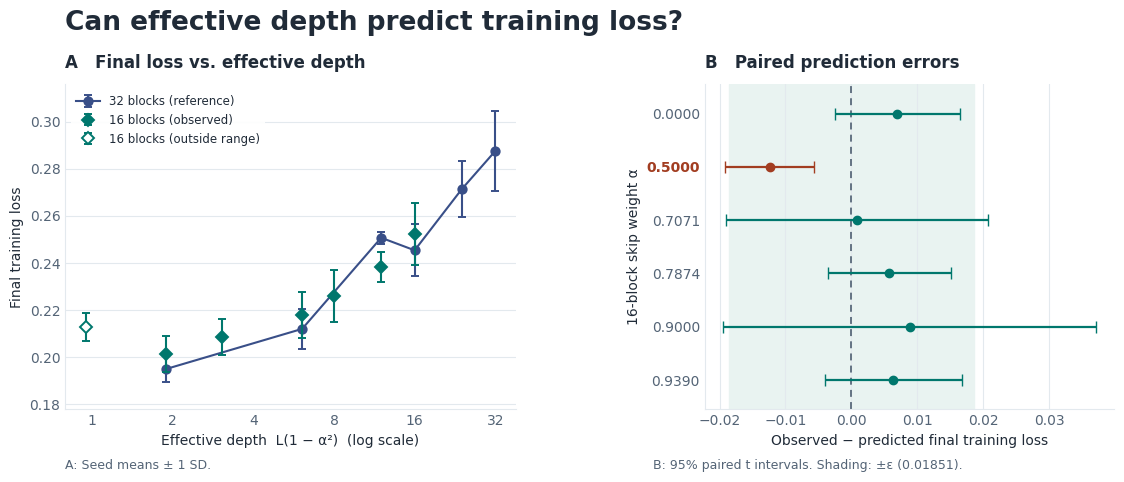

In [26]:
import matplotlib.pyplot as plt

def plot_effective_depth_summary(report):
    observed_color, reference_color, distinct_color = "#00776D", "#394F88", "#A23D21"
    ink, muted, grid = "#202B38", "#546476", "#E3E9EE"
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10, "text.color": ink,
                         "axes.labelcolor": ink, "axes.edgecolor": grid,
                         "xtick.color": muted, "ytick.color": muted, "figure.facecolor": "white",
                         "axes.facecolor": "white", "grid.color": grid}):
        fig, (left, right) = plt.subplots(1, 2, figsize=(11.8, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
        fig.subplots_adjust(left=0.086, right=0.975, bottom=0.19, top=0.815, wspace=0.44)
        fig.suptitle("Can effective depth predict training loss?", x=0.086, y=0.958,
                     ha="left", fontsize=19, fontweight="bold")

        stats = report["condition_stats"]
        predicted_alphas = {row["alpha"] for row in report["rows"]}

        def plot_losses(depth, alphas, color, marker, label, *, connected=False, filled=True):
            keys = sorted(((depth, a) for a in alphas), key=lambda key: C.effective_depth(*key))
            x = [C.effective_depth(*key) for key in keys]
            means, sds = zip(*(stats[key] for key in keys))
            left.errorbar(x, means, yerr=sds, color=color, marker=marker, markersize=6,
                          markerfacecolor=color if filled else "white", markeredgewidth=1.4,
                          capsize=3, linewidth=1.5, linestyle="-" if connected else "none",
                          label=label, zorder=3 if depth == 16 else 2)

        plot_losses(32, C.ALPHAS[32], reference_color, "o", "32 blocks (reference)", connected=True)
        plot_losses(16, predicted_alphas, observed_color, "D", "16 blocks (observed)")
        observed_only = [a for a in C.ALPHAS[16] if a not in predicted_alphas]
        if observed_only:
            plot_losses(16, observed_only, observed_color, "D", "16 blocks (outside range)", filled=False)
        left.set_xscale("log")
        left.set_xticks([1, 2, 4, 8, 16, 32], ["1", "2", "4", "8", "16", "32"])
        left.minorticks_off()
        left.margins(x=0.05, y=0.10)
        left.set_title("A   Final loss vs. effective depth", loc="left", fontsize=12, fontweight="bold", pad=12)
        left.set_xlabel("Effective depth  L(1 − α²)  (log scale)")
        left.set_ylabel("Final training loss")
        left.grid(axis="y", linewidth=0.8)
        left.legend(loc="upper left", fontsize=8.5, facecolor="white", edgecolor="none", framealpha=0.92)

        epsilon = report["epsilon"]
        right.axvspan(-epsilon, epsilon, color="#E9F3F1", zorder=0)
        right.axvline(0, color=muted, linestyle=(0, (4, 3)), linewidth=1.25, zorder=2)
        labels = []
        outside_zero = []
        for i, row in enumerate(report["rows"]):
            error, (low, high) = row["error"], row["ci95"]
            excludes_zero = low > 0 or high < 0
            color = distinct_color if excludes_zero else observed_color
            right.errorbar(error, i, xerr=[[error - low], [high - error]], fmt="o",
                           color=color, markersize=6, capsize=4, linewidth=1.6, zorder=3)
            labels.append(f"{row['alpha']:.4f}")
            outside_zero.append(excludes_zero)
        right.set_yticks(range(len(labels)), labels)
        right.set_ylim(len(labels) - 0.45, -0.55)
        for label, distinct in zip(right.get_yticklabels(), outside_zero):
            if distinct:
                label.set(color=distinct_color, fontweight="bold")
        right.set_title("B   Paired prediction errors", loc="left", fontsize=12, fontweight="bold", pad=12)
        right.set_ylabel("16-block skip weight α")
        right.set_xlabel("Observed − predicted final training loss")
        right.grid(axis="x", linewidth=0.8, zorder=0.5)

        for ax in (left, right):
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(length=0)
        fig.text(0.086, 0.075, "A: Seed means ± 1 SD.", fontsize=9, color=muted)
        fig.text(0.584, 0.075, f"B: 95% paired t intervals. Shading: ±ε ({epsilon:.5f}).",
                 fontsize=9, color=muted)
    return fig

effective_depth_figure = plot_effective_depth_summary(prediction)
plt.show()

### Result

All six absolute mean errors were below the practical margin (ε = 0.01851). At α = 0.5, the
16-block model's final training loss was lower than predicted: the mean error was −0.01240
(95% paired t interval [−0.01910, −0.00569]). The other five intervals included zero.

The pre-registered verdict is **not sure**. Not all intervals included zero, but only one
excluded zero, so the criterion of two deviations in the same direction was not met.

## 9. Sensitivity check: 32 blocks, 12 epochs, selected learning rates

In [41]:
SENS_TAG = "sens"

if not QUICK:
    selected_lrs = load_selected_lr()
    depth = C.DEPTH_MAIN

    for alpha in C.ALPHAS[depth]:
        lr = selected_lrs[(depth, alpha)]
        for seed in C.FINAL_SEEDS:
            run = {
                "depth": depth,
                "width": C.WIDTH,
                "alpha": alpha,
                "lr": lr,
                "seed": seed,
                "epochs": C.EPOCHS_SENSITIVITY,
            }

            if result_exists(**run, tag=SENS_TAG):
                print(f"alpha={alpha:.4f}, seed={seed}: already saved, skipping")
                continue

            result = train_one_run(**run, save=True, tag=SENS_TAG)
            print(
                f"alpha={alpha:.4f}, lr={lr:g}, seed={seed}, "
                f"diverged={result['diverged']}, loss={result['final_train_loss']}",
                flush=True,
            )

alpha=0.0000, lr=0.003, seed=1, diverged=False, loss=0.24660087829589844
alpha=0.0000, lr=0.003, seed=2, diverged=False, loss=0.22580116760253907
alpha=0.0000, lr=0.003, seed=3, diverged=False, loss=0.21892386169433595
alpha=0.5000, lr=0.001, seed=1, diverged=False, loss=0.22636639434814454
alpha=0.5000, lr=0.001, seed=2, diverged=False, loss=0.20345208190917968
alpha=0.5000, lr=0.001, seed=3, diverged=False, loss=0.1936332275390625
alpha=0.7071, lr=0.002, seed=1, diverged=False, loss=0.19630161499023438
alpha=0.7071, lr=0.002, seed=2, diverged=False, loss=0.18504112609863282
alpha=0.7071, lr=0.002, seed=3, diverged=False, loss=0.17493616455078126
alpha=0.7906, lr=0.001, seed=1, diverged=False, loss=0.18583702926635742
alpha=0.7906, lr=0.001, seed=2, diverged=False, loss=0.17324685119628908
alpha=0.7906, lr=0.001, seed=3, diverged=False, loss=0.17316376068115236
alpha=0.9000, lr=0.005, seed=1, diverged=False, loss=0.15911751922607423
alpha=0.9000, lr=0.005, seed=2, diverged=False, loss

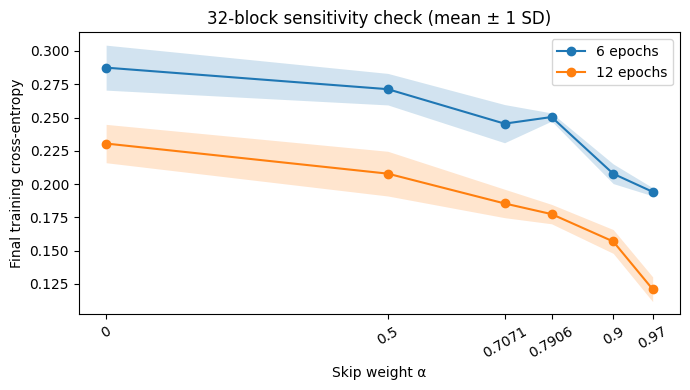

In [44]:
depth = C.DEPTH_MAIN
alphas = sorted(C.ALPHAS[depth])
seeds = tuple(C.FINAL_SEEDS)
selected_lrs = load_selected_lr()

fig, ax = plt.subplots(figsize=(7, 4))

for epochs, tag in ((C.EPOCHS, "final"), (C.EPOCHS_SENSITIVITY, "sens")):
    losses_by_alpha = []

    for alpha in alphas:
        records = load_results(
            tag=tag,
            depth=depth,
            width=C.WIDTH,
            alpha=alpha,
            lr=selected_lrs[(depth, alpha)],
            epochs=epochs,
        )
        records = sorted(
            (run for run in records if run["seed"] in seeds),
            key=lambda run: run["seed"],
        )
        assert tuple(run["seed"] for run in records) == seeds, (tag, alpha)
        assert all(not run["diverged"] for run in records), (tag, alpha)

        losses_by_alpha.append([run["final_train_loss"] for run in records])

    plot_mean_sd(
        ax, alphas, np.asarray(losses_by_alpha).T,
        label=f"{epochs} epochs", marker="o",
    )

ax.set(xlabel="Skip weight α", ylabel="Final training cross-entropy",
       title="32-block sensitivity check (mean ± 1 SD)")
ax.set_xticks(alphas)
ax.set_xticklabels([f"{alpha:.4f}".rstrip("0").rstrip(".") for alpha in alphas])
ax.tick_params(axis="x", labelrotation=30)
ax.legend()
fig.tight_layout()
plt.show()

**Sensitivity to the training budget.** We compared six and twelve epochs
for the 32-block networks using the same selected learning rate and seeds
1–3 for each skip weight. The figure shows the mean and one sample
standard deviation across the three seeds.

Mean final training loss was lower after twelve epochs at all six skip
weights. Both training budgets gave the lowest mean loss at α = 0.97.
The overall downward trend with increasing α persisted, although the
small rise between α ≈ 0.7071 and α ≈ 0.7906 at six epochs became a drop
at twelve epochs. Thus, the broad pattern persisted while the local
ordering of those two conditions changed.

## 10. Optional parameter-matched control

Design: see `C.PARAM_MATCHED`.

Results:

In [28]:
if not QUICK:
    pass  # TODO (only if time allows, priority 4)

## 11. Conclusions and scope

**Effective-depth prediction.** At the six-epoch training budget, the 32-block curve gave small
mean prediction errors for the 16-block models, but the paired results did not resolve whether
effective depth alone was enough. Both interpolated comparisons used only three seed pairs, and
their intervals included errors larger than the practical margin. An interval that includes zero
does not establish a practically small error. The conclusion is limited to the tested models and
training budget.

In [29]:
print(f"Total runtime: {time.time() - T0:.0f} s  (QUICK = {QUICK}; must stay under 300 s when QUICK)")

Total runtime: 1 s  (QUICK = True; must stay under 300 s when QUICK)
